Enter initial window size (odd number):  3
Enter maximum window size Smax (odd number):  7


C:\Users\HP\AppData\Local\Temp\ipykernel_2364\3165526910.py:69: RuntimeWarning: overflow encountered in scalar subtract
  B2 = Zxy - Zmax



PSNR Comparison
-----------------------------
Noisy Image PSNR       : 17.81 dB
Median Filter PSNR     : 27.50 dB
Adaptive Median PSNR   : 27.50 dB


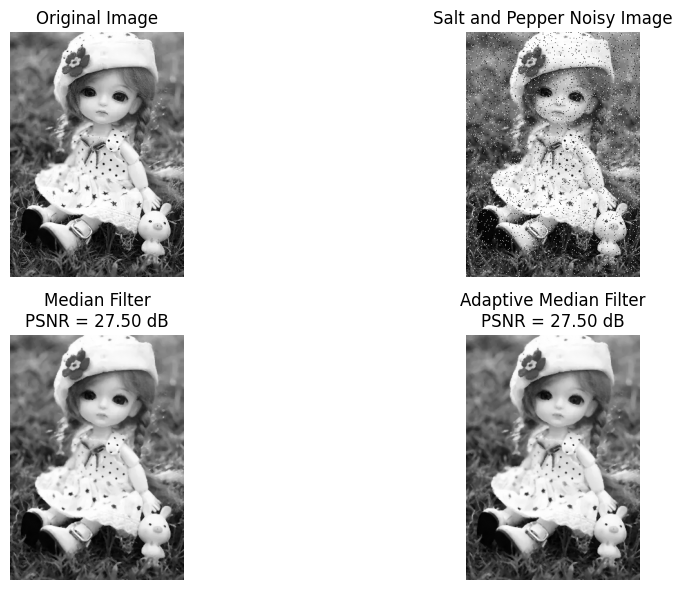


All images saved successfully.


In [3]:
# Write a program to denoise the input image using adaptive median filter. Input the initial window size and maximum size of window (Smax) from the user. Compare the performance of median filter and adaptive median filter, using the PSNR values.  

import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("input.jpg", cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("Please place input.jpg in the same folder.")

Smin = int(input("Enter initial window size (odd number): "))
Smax = int(input("Enter maximum window size Smax (odd number): "))

if Smin < 3 or Smin % 2 == 0:
    raise ValueError("Initial window size must be odd and >= 3.")

if Smax < Smin or Smax % 2 == 0:
    raise ValueError("Smax must be odd and >= initial window size.")
def add_salt_pepper_noise(image, amount=0.05):
    noisy = image.copy()

    total_pixels = image.size
    num_noise = int(amount * total_pixels)
    coords = np.random.randint(0, total_pixels, num_noise)
    salt = coords[:num_noise // 2]
    noisy.flat[salt] = 255
    pepper = coords[num_noise // 2:]
    noisy.flat[pepper] = 0
    return noisy

np.random.seed(42)

noisy_img = add_salt_pepper_noise(img, amount=0.05)

median_img = cv2.medianBlur(noisy_img, Smin)
def adaptive_median_filter(image, Smin, Smax):
    rows, cols = image.shape
    output = image.copy()
    pad = Smax // 2

    padded = cv2.copyMakeBorder(
        image, pad, pad, pad, pad,
        cv2.BORDER_REFLECT
    )

    for i in range(rows):
        for j in range(cols):

            window_size = Smin

            while True:

                radius = window_size // 2
                window = padded[
                    i + pad - radius : i + pad + radius + 1,
                    j + pad - radius : j + pad + radius + 1
                ]

                Zmin = np.min(window)
                Zmax = np.max(window)
                Zmed = np.median(window)
                Zxy = padded[i + pad, j + pad]
                A1 = Zmed - Zmin
                A2 = Zmed - Zmax

                if A1 > 0 and A2 < 0:

                    B1 = Zxy - Zmin
                    B2 = Zxy - Zmax

                    if B1 > 0 and B2 < 0:
                        output[i, j] = Zxy
                    else:
                        output[i, j] = Zmed

                    break

                else:

                    window_size += 2

                    if window_size > Smax:
                        output[i, j] = Zmed
                        break

    return output.astype(np.uint8)

adaptive_img = adaptive_median_filter(
    noisy_img, Smin, Smax
)

def calculate_psnr(original, denoised):

    mse = np.mean(
        (original.astype(np.float64) -
         denoised.astype(np.float64)) ** 2
    )

    if mse == 0:
        return float("inf")
    psnr = 10 * np.log10((255 ** 2) / mse)
    return psnr

psnr_noisy = calculate_psnr(img, noisy_img)
psnr_median = calculate_psnr(img, median_img)
psnr_adaptive = calculate_psnr(img, adaptive_img)

print("\nPSNR Comparison")
print("-----------------------------")
print(f"Noisy Image PSNR       : {psnr_noisy:.2f} dB")
print(f"Median Filter PSNR     : {psnr_median:.2f} dB")
print(f"Adaptive Median PSNR   : {psnr_adaptive:.2f} dB")
plt.figure(figsize=(12, 6))
plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(noisy_img, cmap="gray")
plt.title("Salt and Pepper Noisy Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(median_img, cmap="gray")
plt.title(f"Median Filter\nPSNR = {psnr_median:.2f} dB")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(adaptive_img, cmap="gray")
plt.title(f"Adaptive Median Filter\nPSNR = {psnr_adaptive:.2f} dB")
plt.axis("off")

plt.tight_layout()
plt.show()
cv2.imwrite("noisy_image.jpg", noisy_img)
cv2.imwrite("median_filtered.jpg", median_img)
cv2.imwrite("adaptive_median_filtered.jpg", adaptive_img)
print("\nAll images saved successfully.")

Optimal threshold value: 150.0


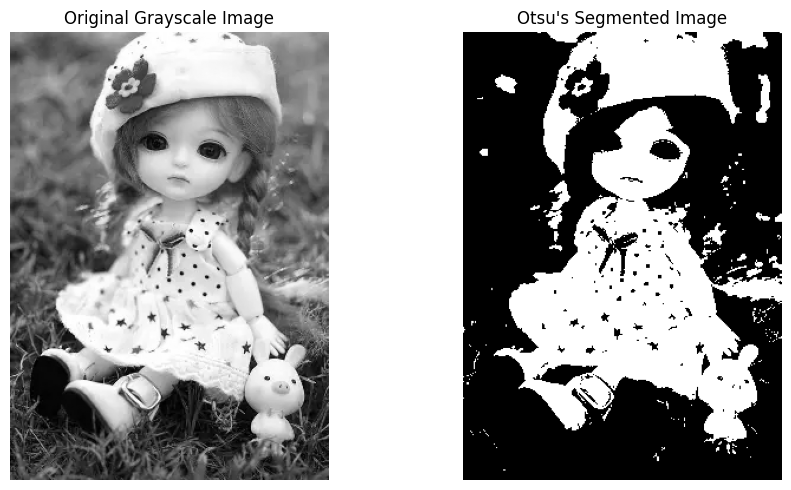

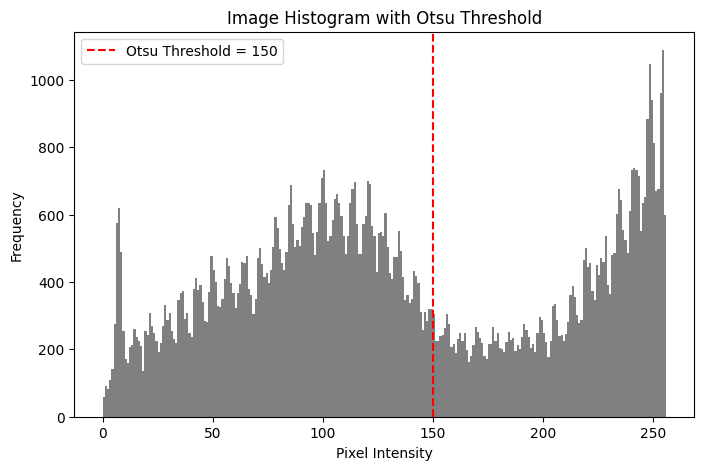

Otsu thresholding completed successfully.
Output saved as otsu_segmented.jpg


In [4]:
#  Write a program to threshold the image using Otsu's global threshold for segmentation of input gray scale image.  

import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("input.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Please place input.jpg in the same folder.")
threshold_value, segmented_img = cv2.threshold(
    img,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Optimal threshold value:", threshold_value)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(segmented_img, cmap="gray")
plt.title("Otsu's Segmented Image")
plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(img.ravel(), bins=256, range=(0, 256), color="gray")
plt.axvline(
    threshold_value,
    color="red",
    linestyle="dashed",
    label=f"Otsu Threshold = {threshold_value:.0f}"
)

plt.title("Image Histogram with Otsu Threshold")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.legend()
plt.show()

cv2.imwrite("otsu_segmented.jpg", segmented_img)
print("Otsu thresholding completed successfully.")
print("Output saved as otsu_segmented.jpg")